In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = "data/archive/"

players = pd.read_csv(DATA + "players.csv")
appearances = pd.read_csv(DATA + "appearances.csv")
competitions = pd.read_csv(DATA + "competitions.csv")

for navn, df in [("players", players), ("appearances", appearances), ("competitions", competitions)]:
    print(navn, df.shape)
    print(list(df.columns), "\n")

players (50149, 26)
['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur'] 

appearances (1894350, 13)
['appearance_id', 'game_id', 'player_id', 'player_club_id', 'player_current_club_id', 'date', 'player_name', 'competition_id', 'yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played'] 

competitions (65, 11)
['competition_id', 'competition_code', 'name', 'sub_type', 'type', 'country_id', 'country_name', 'domestic_league_code', 'confederation', 'total_clubs', 'url'] 



In [3]:
players.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


In [4]:
appearances.head()

,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,2234418_73333,2234418,73333,1274,76,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90


In [5]:
competitions.head()

,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code,confederation,total_clubs,url
0,A1,bundesliga,bundesliga,first_tier,domestic_league,127,Austria,A1,europa,12.0,https://www.transfermarkt.co.uk/bundesliga/sta...
1,AFAC,afc-asian-cup,afc-asian-cup,afc_asian_cup,national_team_competition,-1,NaN,NaN,asien,NaN,https://www.transfermarkt.co.uk/afc-asian-cup/...
2,AFCN,africa-cup-of-nations,africa-cup-of-nations,africa_cup_of_nations,national_team_competition,-1,NaN,NaN,afrika,NaN,https://www.transfermarkt.co.uk/africa-cup-of-...
3,ARG1,torneo-apertura,torneo-apertura,first_tier,domestic_league,9,Argentina,ARG1,amerika,30.0,https://www.transfermarkt.co.uk/torneo-apertur...
4,AUS1,a-league-men,a-league-men,first_tier,domestic_league,12,Australia,AUS1,asien,12.0,https://www.transfermarkt.co.uk/a-league-men/s...


In [6]:
competitions[competitions["name"].str.contains("champions", case=False)][["competition_id", "name", "type"]]

,competition_id,name,type
12,CL,uefa-champions-league,international_cup
13,CLQ,uefa-champions-league-qualifying,international_cup
28,FRCH,trophee-des-champions,other


In [7]:
players["last_season"].value_counts().sort_index()

last_season
2012     1658
2013     2061
2014     1660
2015     1651
2016     1831
2017     1661
2018     2065
2019     1566
2020     1843
2021     1817
2022     1877
2023     2092
2024     6075
2025    22292
Name: count, dtype: int64

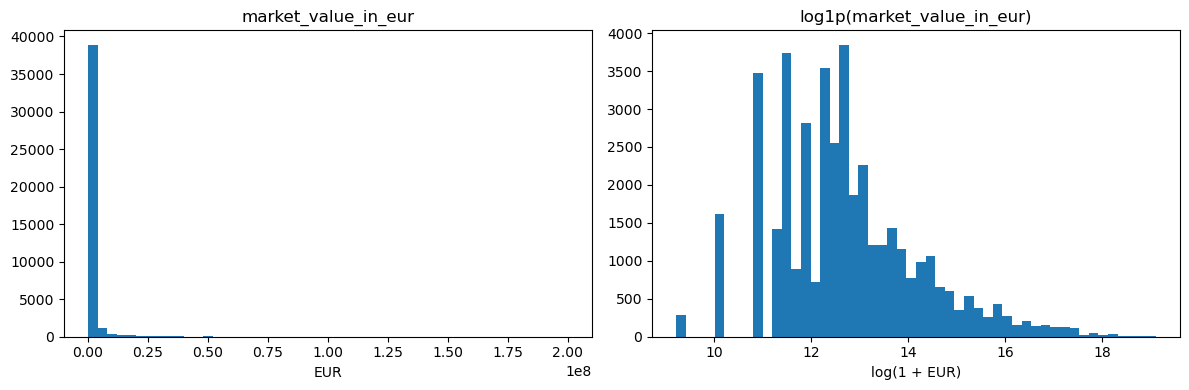

Manglende verdier: 8621
Skjevhet før: 11.75  etter: 0.7


In [8]:
mv = players["market_value_in_eur"].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(mv, bins=50)
ax[0].set_title("market_value_in_eur")
ax[0].set_xlabel("EUR")

ax[1].hist(np.log1p(mv), bins=50)
ax[1].set_title("log1p(market_value_in_eur)")
ax[1].set_xlabel("log(1 + EUR)")

plt.tight_layout()
plt.show()

print("Manglende verdier:", players["market_value_in_eur"].isna().sum())
print("Skjevhet før:", round(mv.skew(), 2), " etter:", round(np.log1p(mv).skew(), 2))